# First cosmological analysis: inferring ($\sigma_8, b_g$) from galaxy auto and galaxy x cmb lensing

- The first and second CoLoRe simulation boxes were generated by Laura Casas, Dani L. Jarque run the rest from then on.
- The notebook uses the sources output from CoLoRe, i.e. quasars, to validate the simulation through the auto-spectrum and cross spectrum with CMB lensing.
    - The kappa map (`out_kappa_z000.fits`) can be found in `./data/test_box_x/results/`.
    - The QSO catalogs (`out_srcs_sx_xx.fits`) can be found in `./data/test_box_x/results)/`.
    - The galaxies auto-spectrum $C_{\ell}^{gg}$ and kappa $\times$ galaxies cross-spectrum $C_{\ell}^{\kappa g}$ can be found in `./data/test_box_x/cls/` with the corresponding errorbars, and a logarithmic rebinning run with `./scripts/generate_rebinned_cls.py`.
- The notebook also fits for two parameters in the modelling accounting for CoLoRe finite cell size and a rescaling of the theory bias.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import camb
import healpy as hp

from scipy.optimize import minimize
from scipy.interpolate import PchipInterpolator
from scipy.integrate import simpson
from scipy.constants import c
import zeus, corner
import sys
sys.path.append('../')

from utils.rebinning import hybrid_bin_cls
import json

# functions

## theory

In [2]:
def load_cosmology(filename):
    with open(filename) as f:
        return json.load(f)

In [3]:
def get_camb_results(
    cosmo_dict,
    z_pk,
    kmax=100.0,
    lmax=2500,
    nonlinear=False,
):
    """
    Read a cosmological parameter dictionary, extract cosmological parameters,
    and build CAMB results instance
    """

    # Convert to CAMB inputs

    H0 = 100.0 * cosmo_dict["h"]
    ombh2 = cosmo_dict["omega_B"] * cosmo_dict["h"]**2
    omch2 = (cosmo_dict["omega_M"] - cosmo_dict["omega_B"]) * cosmo_dict["h"]**2

    # Initial CAMB params

    pars = camb.CAMBparams()
    pars.set_cosmology(
        H0=H0,
        ombh2=ombh2,
        omch2=omch2,
    )
    pars.set_dark_energy(w=cosmo_dict["w"])
    pars.InitPower.set_params(
        ns=cosmo_dict["ns"],
        As=cosmo_dict["As"]
    )

    # Matter power settings

    pars.set_matter_power(
        redshifts=z_pk,
        kmax=kmax
    )

    # note that to get CAMB's internal calculation accurate at the 1% level at L~2000,
    # need lens_potential_accuracy=2. Increase to 4 for accurate match to the Limber calculation here
    if nonlinear:
        pars.NonLinear = camb.model.NonLinear_pk
        pars.set_for_lmax(lmax=lmax, lens_potential_accuracy=4, nonlinear=True)
    else:
        pars.set_for_lmax(lmax=lmax, lens_potential_accuracy=4, nonlinear=False)

    # Final results
    results = camb.get_results(pars)

    return results

In [4]:
def W_g(z, kernel_context, kernel_args):
    '''
    Galaxy clustering kernel.
    '''

    # jacobian of transforming n(chi)=dN/dchi to n(z)=dN/dz, i.e. dchi/dz 
    c_kms = c * 1e-3
    Hz = kernel_context["Hz"]

    bz_interp = kernel_args["bz_interp"]
    nz_interp = kernel_args["nz_interp"]

    bias = bz_interp(z)
    ndensity = nz_interp(z)

    return bias * ndensity * (Hz / c_kms)

In [5]:
def W_kappa(z, kernel_context, kernel_args):
    '''
    CMB lensing convergence kernel.
    '''

    # geometry
    a = 1.0 / (1.0 + z)

    # comoving distance to lens and source
    chi = kernel_context["chi"]
    chi_source = kernel_context["chi_source"]

    # cosmological parameters
    H0, om = kernel_context["cosmo_params"]
    c_kms = c * 1e-3

    # kernel prefactor
    W_prefactor = 1.5 * (H0 / c_kms)**2 * om * (chi_source - chi) / chi_source
    W_geom = chi / a

    return W_prefactor * W_geom

## data

In [6]:
def get_colore_cls(box_filename):
    '''
    Load the Colore kappa power spectrum from a text file
    '''

    # load the data from the .npz file
    data = np.load(box_filename)

    return data['ells'], data['cls'], data['err'], data['nside'], data['shot_noise']

## fitting

In [7]:
def get_limber_cls_fit(
    params,
    z_grid,
    pk_interp_lin,
    kernel1_grid,
    kernel2_grid,
    kernel_context,
    pixwin_gg,
    pixwin_kg,
    lmin_fit,
    lmax_fit,
    sigma8_fid,
    kmax=100,
):
    '''
    Compute the angular qq/kq power spectra using the Limber approximation.
    '''

    # fitting parameters
    Abias, kp_gg, kp_kg, sigma8 = params

    # multipoles and cls
    ells = np.arange(lmin_fit, lmax_fit + 1)
    cls_gg = np.zeros_like(ells, dtype=np.float64)
    cls_kg = np.zeros_like(ells, dtype=np.float64)

    # geometry
    chi = kernel_context["chi"][:, None]        # (Nz,1)
    Hz = kernel_context["Hz"][:, None]          # (Nz,1)
    c_kms = c * 1e-3

    # Limber k-grid (Nz, Nell)
    k = (ells[None, :] + 0.5) / chi

    # valid CAMB region
    mask = (k > 1e-4) & (k < kmax)

    # evaluate P(k,z) for all z and ell
    pk = np.zeros_like(k)
    pk[mask] = pk_interp_lin.P(
        np.broadcast_to(z_grid[:, None], k.shape)[mask],
        k[mask],
        grid=False,
    )

    # parameter-dependent smoothing
    smooth_gg = np.exp(-(k / kp_gg) ** 2)
    smooth_kg = np.exp(-(k / kp_kg) ** 2)

    # full integrand
    base_gg = (c_kms / Hz) * (kernel1_grid[:, None] * kernel1_grid[:, None]) / chi**2
    base_kg = (c_kms / Hz) * (kernel1_grid[:, None] * kernel2_grid[:, None]) / chi**2
    integrand_gg = base_gg * pk * smooth_gg
    integrand_kg = base_kg * pk * smooth_kg

    # integrate all multipoles simultaneously
    cls_gg = Abias**2 * (sigma8/sigma8_fid)**2 * simpson(
        integrand_gg,
        x=z_grid,
        axis=0,
    )

    cls_kg = Abias * (sigma8/sigma8_fid)**2 * simpson(
        integrand_kg,
        x=z_grid,
        axis=0,
    )
    
    # match the healpix pixel window function with length of cls
    lmax_map1 = len(pixwin_gg) - 1
    lmax_map2 = len(pixwin_kg) - 1
    lmax_min = np.min([lmax_map1, lmax_map2, lmax_fit])
    pixwin_gg = pixwin_gg[lmin_fit : (lmax_min + 1)]
    pixwin_kg = pixwin_kg[lmin_fit : (lmax_min + 1)]
    ells = ells[:(lmax_min + 1 - lmin_fit)]
    cls_gg = cls_gg[:(lmax_min + 1 - lmin_fit)]
    cls_kg = cls_kg[:(lmax_min + 1 - lmin_fit)]
    cls_gg_smoothed = cls_gg * (pixwin_gg ** 2)
    cls_kg_smoothed = cls_kg * (pixwin_kg ** 2)

    return {
        "ells": ells,
        "cls_gg": cls_gg_smoothed,
        "cls_kg": cls_kg_smoothed,
    }

In [8]:
def get_chi2(
    params,
    z_grid,
    lmin_fit,
    lmax_fit,
    nbins_fit,
    pk_interp_lin,
    kernel1_grid,
    kernel2_grid,
    kernel_context,
    pixwin_gg,
    pixwin_kg,
    cls_data,
    invcov_mat,
    sigma8_fid,
    kmax=100.0,
):
    '''
    Reduced chi-squared for gg and gk fitting.
    '''

    # compute theory
    results = get_limber_cls_fit(
        params,
        z_grid,
        pk_interp_lin,
        kernel1_grid,
        kernel2_grid,
        kernel_context,
        pixwin_gg,
        pixwin_kg,
        lmin_fit,
        lmax_fit,
        sigma8_fid,
        kmax=kmax,
    )

    # rebin theory
    _, cls_theory_gg, _ = hybrid_bin_cls(
        results["ells"],
        results["cls_gg"],
        nbins=nbins_fit,
        ell_min=lmin_fit,
        ell_max=lmax_fit,
    )

    _, cls_theory_kg, _ = hybrid_bin_cls(
        results["ells"],
        results["cls_kg"],
        nbins=nbins_fit,
        ell_min=lmin_fit,
        ell_max=lmax_fit,
    )

    # create theory vector
    cls_theory = np.concatenate((cls_theory_gg, cls_theory_kg))

    # remove invalid values
    mask = np.isfinite(cls_data)
    cls_data = cls_data[mask]
    cls_theory = cls_theory[mask]

    # get chi2 statistic
    chi2 = (cls_data - cls_theory) @ invcov_mat @ (cls_data - cls_theory).T
    
    return chi2

## sampler

In [9]:
def log_prior(theta):
    '''
    Flat priors on kp and A_bias.
    '''

    Abias, kp_gg, kp_kg, sigma8 = theta

    if 0 < sigma8 < 10.0 and 0.5 < Abias < 1.5 and 0.01 < kp_gg < 100.0 and 0.01 < kp_kg < 100.0:
        return 0.0

    return -np.inf

In [10]:
def log_posterior(
    theta,
    z_grid,
    lmin_fit,
    lmax_fit,
    nbins_fit,
    pk_interp_lin,
    kernel1_grid,
    kernel2_grid,
    kernel_context,
    pixwin_gg,
    pixwin_kg,
    cls_data,
    invcov_data,
    sigma8_fid,
    kmax=100.0,
):

    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf

    chi2 = get_chi2(
        theta,
        z_grid,
        lmin_fit,
        lmax_fit,
        nbins_fit,
        pk_interp_lin,
        kernel1_grid,
        kernel2_grid,
        kernel_context,
        pixwin_gg,
        pixwin_kg,
        cls_data,
        invcov_data,
        sigma8_fid,
        kmax)

    return lp - 0.5 * chi2

# Fitting sample

## boltzmann parameters

In [11]:
# set the redshift range for the boltzmann solver
zmin, zmax = 0, 1100
nz = 200
z_pk = zmin + np.exp(np.log(zmax - zmin + 1)*np.linspace(0, 1, nz)) - 1
z_pk = z_pk[::-1] # reverse to have higher redshift first for better interpolation at high z
lmin, lmax = 2, 2500

## measure and compare output n(z)

In [12]:
# choose the box for which to compare the theory and the CoLoRe Cls
box = 'test_box_4'  # options: 'third_test_box', 'fourth_test_box'
galaxy_catalog = 'lsst_gal'  # options: 'desi_bgs, 'desi_lrg', 'desi_qso', 'lsst_gal'
params_path = f'../data/{box}/cosmo_params.json'

In [13]:
# load the galaxy catalogs, galaxy bias and redshift distribution, 
z_bz, bz = np.loadtxt(f'../data/colore_files/bz/bz_{galaxy_catalog}.txt', unpack=True)
z_nz_input, nz_input = np.loadtxt(f'../data/colore_files/nz/nz_{galaxy_catalog}.txt', unpack=True)
zbin_width_input = np.diff(z_nz_input)[0]

# load the n(z) histogram output from colore
z_edges, nz_output = np.load(f'../data/{box}/cls/nz_hist_{galaxy_catalog}.npz')['z_edges'], np.load(f'../data/{box}/cls/nz_hist_{galaxy_catalog}.npz')['nz']
zbin_width_output = np.diff(z_edges)[0]

# create n(z) interpolator for the input galaxy bias and redshift distribution
fsky = (4 * np.pi) * (180 / np.pi)**2  # multiply by the total sky area in deg**2 and redshift bin width
nz_input = nz_input * fsky * zbin_width_output
norm = simpson(nz_input, z_nz_input)
nz_interp_input = PchipInterpolator(z_nz_input, nz_input, extrapolate=False)
bz_interp = PchipInterpolator(z_bz, bz, extrapolate=False)

In [14]:
# full redshift range for interpolation plot
zmin = 0.0
zmax = 3.8
z = np.linspace(zmin, zmax, 1000)

# create n(z) interpolator for the output redshift distributions
z_nz_output = 0.5*(z_edges[:-1] + z_edges[1:])  # get the bins middle points
z_nz_output = np.concatenate(([zmin], z_nz_output, [zmax]))  # add the first and last bin edges to the middle points redshift
z_nz_output_min = nz_input[0]
z_nz_output_max = nz_input[np.abs(z_nz_input - 3.8).argmin()]

nz_output = np.concatenate(([z_nz_output_min], nz_output, [z_nz_output_max]))  # add the first and last bin edges to the middle points n(z)
nz_interp_output = PchipInterpolator(z_nz_output, nz_output, extrapolate=True)

In [15]:
# define the redshift tomographic bin of the analysis
zmin_bin = 0.0
zmax_bin = 3.8
zbin = np.linspace(zmin_bin, zmax_bin, 1000)
nz_output_bin = nz_output.copy()
nz_output_bin[(z_nz_output <= zmin_bin) | (z_nz_output >= zmax_bin)] = 0  # ensure the interpolator is zero outside the tomographic bin

# create n(z) interpolator for the tomographic bin output redshift distributions
norm = simpson(nz_interp_output(zbin), zbin)
nz_interp_output_bin = PchipInterpolator(z_nz_output, nz_output_bin/norm, extrapolate=True)

/tmp/ipykernel_106129/544734809.py:16: RuntimeWarning: divide by zero encountered in divide
  ratio = (nz_interp_output_bin(z)*norm - (nz_interp_input(z))) / nz_interp_input(z)
/tmp/ipykernel_106129/544734809.py:16: RuntimeWarning: invalid value encountered in divide
  ratio = (nz_interp_output_bin(z)*norm - (nz_interp_input(z))) / nz_interp_input(z)


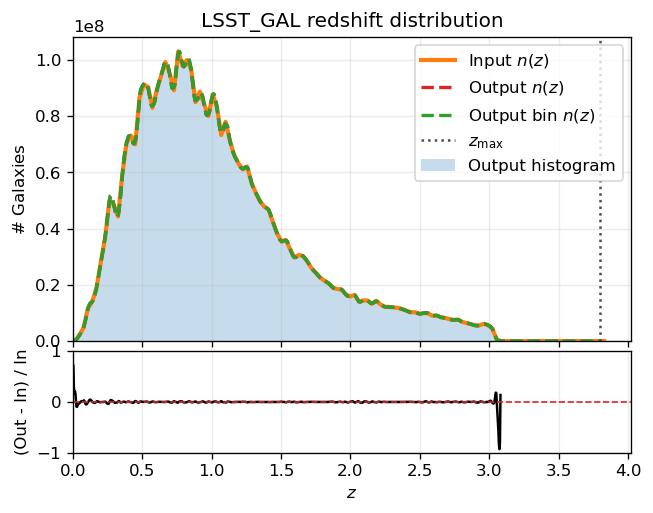

In [16]:
nbins = 400
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 4.5), dpi=120, sharex=True, gridspec_kw={'height_ratios':[3,1], 'hspace':0.05})

# Top panel
ax1.bar(z_nz_output, nz_output, width=zbin_width_output, align='center', color='C0', alpha=0.25, label='Output histogram')  # align=edge is needed to match the histogram bins edges with the bars edges
ax1.plot(z_nz_input, nz_interp_input(z_nz_input), 'C1', lw=2.5, label=r'Input $n(z)$')
ax1.plot(z, nz_interp_output(z), 'C3--', lw=2, label=r'Output $n(z)$')
ax1.plot(z, nz_interp_output_bin(z)*norm, 'C2--', lw=2, label=r'Output bin $n(z)$')
ax1.axvline(3.8, color='0.3', ls=':', lw=1.5, label=r'$z_{\rm max}$')
ax1.set_ylabel(r'$\#$ Galaxies')
ax1.set_title(f'{galaxy_catalog.upper()} redshift distribution')
ax1.legend(frameon=True)
ax1.grid(alpha=0.25)

# Bottom panel
ratio = (nz_interp_output_bin(z)*norm - (nz_interp_input(z))) / nz_interp_input(z)
ratio[(nz_interp_input(z) == 0)] = np.nan # set to nan if nz_output is zero
ratio[(nz_interp_output_bin(z) == 0)] = np.nan # set to nan if nz_output is zero
ax2.plot(z, ratio, 'k', lw=1.5)
ax2.axhline(0, color='C3', ls='--', lw=1)
ax2.set_xlim(left=0)
ax2.set_ylim(-1, 1)
ax2.set_xlabel(r'$z$')
ax2.set_ylabel('(Out - In) / In')
ax2.grid(alpha=0.25)

plt.show()

# First analysis: $\sigma_8$ and $b_g$ fit

The plan is to infer $\sigma_8$ by breaking the degeneracy with galaxy bias $b(z)$ by combining galaxy auto and galaxy x cmb lensing spectrums. Marginalizing over $k_p$ for both galaxy auto and galaxy cross. However, we are working with $A_{\rm bias}$ instead of the bias directly, for validation purpouses, so we will be fitting for this parameter instead of the effective bias over the redshift bin $b_{\rm eff}$.

## preparation

In [17]:
# get cosmological parameters
cosmo_dict = load_cosmology(params_path)
z_max = cosmo_dict["z_max"]
sigma8_fid = cosmo_dict['sigma_8']

# get CAMB results
results_lin = get_camb_results(
    cosmo_dict=cosmo_dict,
    z_pk=z_pk,
    kmax=100,
    lmax=lmax,
    nonlinear=False
)

# get matter power spectrum interpolator
pk_interp_lin = results_lin.get_matter_power_interpolator(
    nonlinear=False,
    hubble_units=False,
    k_hunit=False,
    var1='delta_tot',
    var2='delta_tot'
)

z_star = cosmo_dict["z_out"]
chi_star = results_lin.comoving_radial_distance(z_star)


# cosmological parameters needed by kernels
H0 = cosmo_dict["h"] * 100
om = cosmo_dict["omega_M"]

# shared kernel context
chi_source = chi_star
kernel_context = {
    "results": results_lin,
    "chi_source": chi_source,
    "cosmo_params": (H0, om),
}

# precompute the z, chi(z) and H(z) grids for Limber integrand
z_grid = np.linspace(1e-4, z_max, 1000)
chi_grid = results_lin.comoving_radial_distance(z_grid)
Hz_grid = results_lin.hubble_parameter(z_grid)

# add to kernel context for use in kernels and Limber integrand
kernel_context["chi"] = chi_grid
kernel_context["Hz"] = Hz_grid

# defined the kernel arguments 
kernel1_args={
            "bz_interp": bz_interp,
            "nz_interp": nz_interp_output_bin}
kernel2_args=kernel1_args.copy()

# precompute the kernel grids for Limber integrand
Wk_grid = W_kappa(z_grid, kernel_context, kernel1_args)
Wg_grid = W_g(z_grid, kernel_context, kernel2_args)

In [18]:
# set the fitting range for the chi2 minimization
lmin_fit = 20
lmax_fit = 1500
nbins_fit = 30

In [19]:
# load and rebin gg data
box_path_gg = f'../data/{box}/cls/cl_gg_{galaxy_catalog}.npz'
ells_data, cls_gg_data, err_gg_data, nside_gg, shot_noise = get_colore_cls(box_path_gg)
ells_data_rebin, cls_gg_data_rebin, err_gg_data_rebin = hybrid_bin_cls(
        ells_data,
        cls_gg_data,
        err_gg_data,
        nbins=nbins_fit,
        ell_min=lmin_fit,
        ell_max=lmax_fit,
    )

# load and rebin kg data
box_path_kg = f'../data/{box}/cls/cl_kg_{galaxy_catalog}.npz'
ells_data, cls_kg_data, err_kg_data, nside_kg, shot_noise = get_colore_cls(box_path_kg)
ells_data_rebin, cls_kg_data_rebin, err_kg_data_rebin = hybrid_bin_cls(
        ells_data,
        cls_kg_data,
        err_kg_data,
        nbins=nbins_fit,
        ell_min=lmin_fit,
        ell_max=lmax_fit,
    )

# smooth with healpix pixel window function
pixwin_gg = hp.pixwin(nside_gg)
pixwin_kg = hp.pixwin(nside_kg)

# create data array and covariance matrix
cls_data = np.concatenate((cls_gg_data_rebin, cls_kg_data_rebin))

# compute and rebin covariance off-diagonal terms
fsky = 1
nl_gg = np.ones_like(ells_data) * shot_noise
corr = (2 / ((2*ells_data[:lmax_fit] + 1)*fsky)) * ((cls_gg_data[:lmax_fit] + nl_gg[:lmax_fit]) * cls_kg_data[:lmax_fit])
_, _, corr_rebin = hybrid_bin_cls(
        ells_data[:lmax_fit],
        np.zeros_like(ells_data[:lmax_fit]),
        corr[:lmax_fit],
        nbins=nbins_fit,
        ell_min=lmin_fit,
        ell_max=lmax_fit,
    )
corr_rebin = corr_rebin**2  # hybrid_bin_cls returns the standard deviations, but we need the correlation for the covariance matrix

# construct the covariance matrix between observables
cov_mat = np.block([[np.diag(err_gg_data_rebin**2), np.diag(corr_rebin)],
                    [np.diag(corr_rebin), np.diag(err_kg_data_rebin**2)]])
invcov_mat = np.linalg.inv(cov_mat)

/home/dljarque/Documents/cmb_lensing_lya/notebooks/../utils/rebinning.py:53: UserWarning: ell_min (20) >= ell_switch (20). Skipping linear binning and using logarithmic bins only.
  warnings.warn(


## minimizer

In [20]:
# perform the chi2 minimization
x0 = [1.0, 0.5, 0.5, sigma8_fid]  # initial guess for sigma8, Abias, kp_gg, and kp_kg
bounds = [(0.5, 1.5), (0.01, 1000.0), (0.01, 1000.0), (0.01, 5)]  # bounds for sigma8, Abias, kp_gg, and kp_kg
result = minimize(
    get_chi2,
    x0=x0,
    bounds=bounds,
    method="L-BFGS-B",
    args=(
        z_grid,
        lmin_fit,
        lmax_fit,
        nbins_fit,
        pk_interp_lin,
        Wg_grid,
        Wk_grid,
        kernel_context,
        pixwin_gg,
        pixwin_kg,
        cls_data,
        invcov_mat,
        sigma8_fid,
    )
)

# extract best-fit parameters, covariance and chi2
best_Abias, best_kp_gg, best_kp_kg, best_sigma8  = result.x
cov = result.hess_inv.todense()
errors = np.sqrt(np.diag(cov))
chi2_best = result.fun

In [21]:
print(f"Best-fit sigma8: {best_sigma8:.2f} +/- {errors[3]:.2f}")
print(f"Best-fit A_bias: {best_Abias:.2f} +/- {errors[0]:.2f}")
print(f"Best-fit kp_gg   : {best_kp_gg:.2f} +/- {errors[1]:.2f} 1/Mpc")
print(f"Best-fit kp_kg   : {best_kp_kg:.2f} +/- {errors[2]:.2f} 1/Mpc")
print(f"Reduced chi2 at best-fit: {chi2_best:.2f}")

Best-fit sigma8: 0.81 +/- 3.41
Best-fit A_bias: 1.01 +/- 3.73
Best-fit kp_gg   : 0.40 +/- 0.64 1/Mpc
Best-fit kp_kg   : 0.32 +/- 1.24 1/Mpc
Reduced chi2 at best-fit: 89.82


## sampler

In [22]:
# scipy best fit
theta0 = x0

ndim = 4
nwalkers = 10

# initialize walkers around best fit
start = theta0 + 1e-1 * np.random.randn(nwalkers, ndim)

In [23]:
# initialize the sampler
sampler = zeus.EnsembleSampler(
    nwalkers,
    ndim,
    log_posterior,
    args=(
        z_grid,
        lmin_fit,
        lmax_fit,
        nbins_fit,
        pk_interp_lin,
        Wg_grid,
        Wk_grid,
        kernel_context,
        pixwin_gg,
        pixwin_kg,
        cls_data,
        invcov_mat,
        sigma8_fid,
    )
)

In [24]:
nsteps = 1500
sampler.run_mcmc(start, nsteps, progress=True)

Initialising ensemble of 10 walkers...
Sampling progress : 100%|██████████| 1500/1500 [8:57:38<00:00, 21.51s/it]   


In [25]:
burnin = 250

samples = sampler.get_chain(
    discard=burnin,
    flat=True,
)
truths = [1.0, None, None, sigma8_fid]  # Assuming the true value of A_bias is 1.0 for the purpose of this example
np.savez(f"../data/{box}/chains/chain_{galaxy_catalog}_nsteps{nsteps}.npz", samples=samples, truths=truths)

## plotter

In [40]:
# choose the box for which to compare the theory and the CoLoRe Cls
box = 'test_box_4'  # options: 'third_test_box', 'fourth_test_box'
galaxy_catalog = 'lsst_gal'  # options: 'desi_bgs, 'desi_lrg', 'desi_qso', 'lsst_gal'
chain = np.load(f"../data/{box}/chains/chain_{galaxy_catalog}_nsteps{nsteps}.npz", allow_pickle=True)
samples = chain['samples'][:-1500, :]  # discard the last 1000 samples as burn-in
truths = chain['truths']

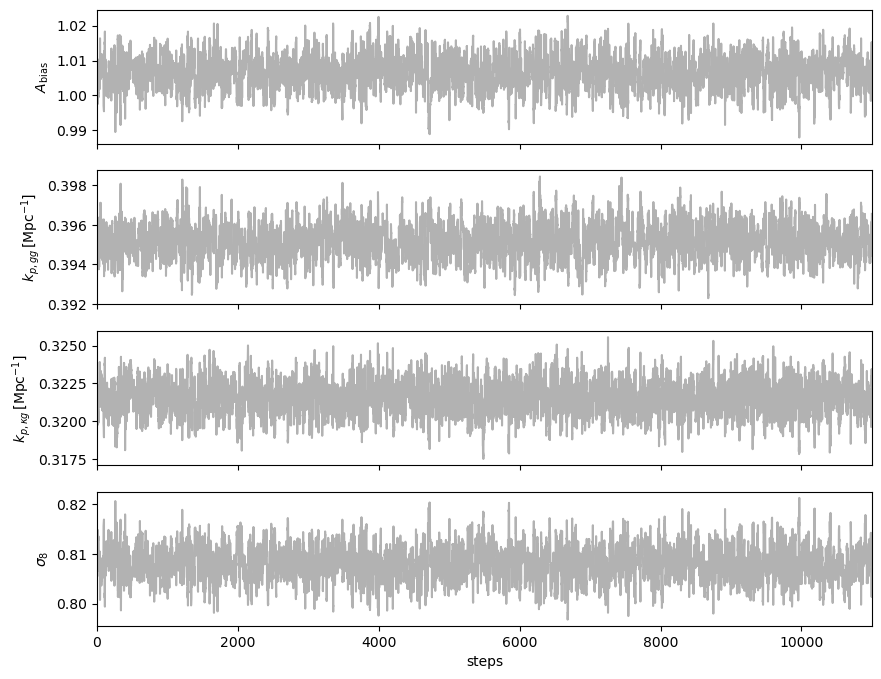

In [41]:
fig, axes = plt.subplots(4, figsize=(10, 8), sharex=True)
axis_labels = [
    r"$A_{\rm bias}$",
    r"$k_{p,gg}\,[\mathrm{Mpc}^{-1}]$",
    r"$k_{p,\kappa g}\,[\mathrm{Mpc}^{-1}]$",
    r"$\sigma_8$",
]

for i in range(4):
    ax = axes[i]
    # Plot the path of all walkers across all steps for this dimension
    ax.plot(samples[:, i], "k", alpha=0.3)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(axis_labels[i])
    axes[3].set_xlabel('steps')

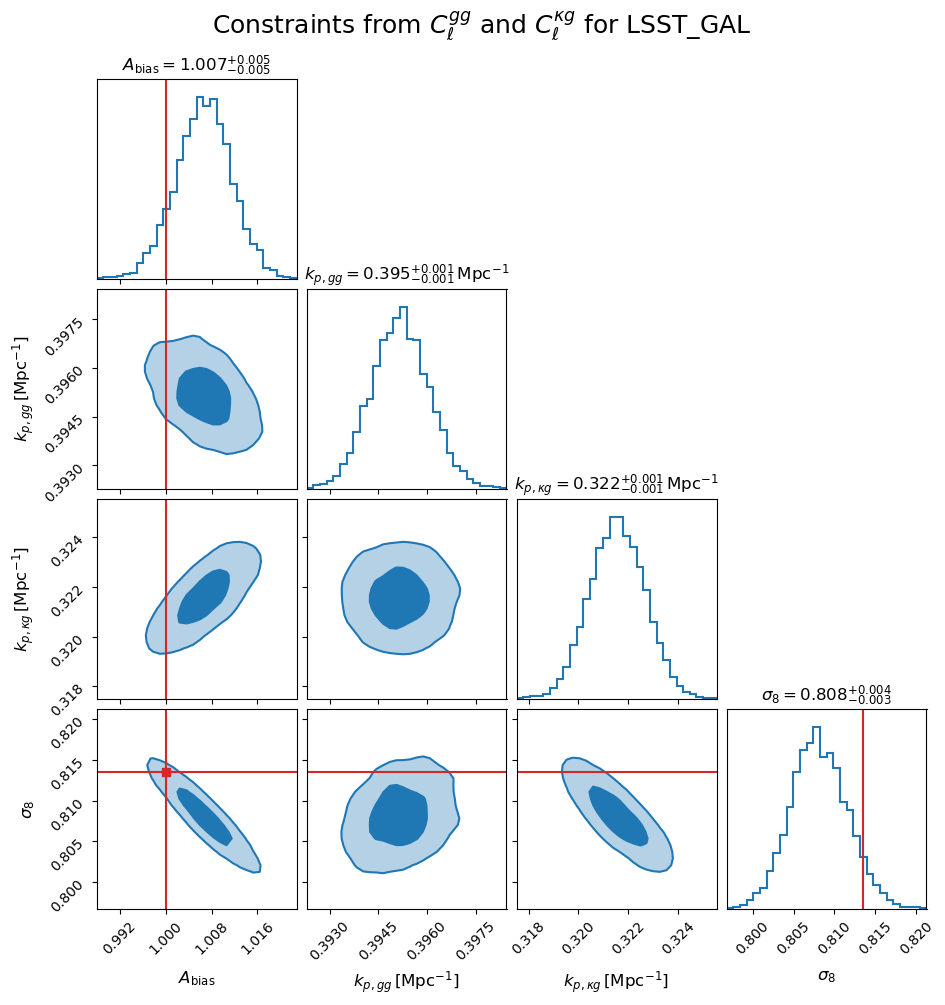

In [45]:
# 1σ and 2σ enclosed probabilities for a 2D Gaussian
levels = [
    1.0 - np.exp(-0.5),  # 1σ ≈ 0.393
    1.0 - np.exp(-2.0),  # 2σ ≈ 0.865
]

fig = corner.corner(
    samples,
    labels=axis_labels,

    # Only show truths for sigma8 and Abias
    truths=truths,

    # Contours
    levels=levels,
    fill_contours=True,
    plot_contours=True,
    color="tab:blue",

    # General appearance
    smooth=1.0,
    bins=30,
    show_titles=True,
    title_fmt=".3f",
    title_kwargs={"fontsize": 12},
    label_kwargs={"fontsize": 12},

    # Samples / contours
    plot_datapoints=False,
    plot_density=False,

    # Truth lines
    truth_color="tab:red",

    # Histograms
    hist_kwargs={
        "density": True,
        "linewidth": 1.5,
    },

    # Contour borders
    contour_kwargs={
        "linewidths": 1.5,
    },
)

fig.suptitle(
    rf"Constraints from $C_\ell^{{gg}}$ and $C_\ell^{{\kappa g }}$ for {galaxy_catalog.upper()}",
    fontsize=18,
    y=1.03,
)
q = np.percentile(samples, [16, 50, 84], axis=0)

titles = [
    rf"$A_{{\rm bias}} = {q[1,0]:.3f}^{{+{q[2,0]-q[1,0]:.3f}}}_{{-{q[1,0]-q[0,0]:.3f}}}$",

    rf"$k_{{p,gg}} = {q[1,1]:.3f}^{{+{q[2,1]-q[1,1]:.3f}}}_{{-{q[1,1]-q[0,1]:.3f}}}\,"
    rf"\mathrm{{Mpc}}^{{-1}}$",

    rf"$k_{{p,\kappa g}} = {q[1,2]:.3f}^{{+{q[2,2]-q[1,2]:.3f}}}_{{-{q[1,2]-q[0,2]:.3f}}}\,"
    rf"\mathrm{{Mpc}}^{{-1}}$",
    rf"$\sigma_8 = {q[1,3]:.3f}^{{+{q[2,3]-q[1,3]:.3f}}}_{{-{q[1,3]-q[0,3]:.3f}}}$",
]

axes = np.asarray(fig.axes).reshape(4, 4)

for i, title in enumerate(titles):
    axes[i, i].set_title(title, fontsize=12)

plt.savefig(f"../data/{box}/chains/corner_plot_{galaxy_catalog}_nsteps{nsteps}.png", dpi=300, bbox_inches="tight")
plt.show()

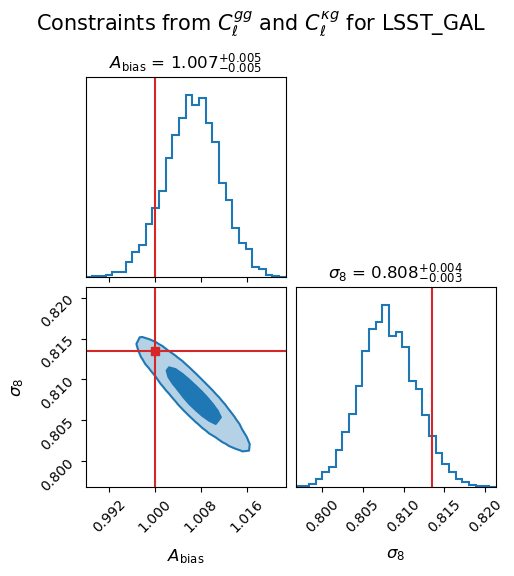

In [48]:
# 1σ and 2σ enclosed probabilities for a 2D Gaussian
levels = [
    1.0 - np.exp(-0.5),  # 1σ ≈ 0.393
    1.0 - np.exp(-2.0),  # 2σ ≈ 0.865
]

fig = corner.corner(
    samples[:, [0, 3]],
    labels=[axis_labels[0], axis_labels[3]],

    # Only show truths for sigma8 and Abias
    truths=[truths[0], truths[3]],

    # Contours
    levels=levels,
    fill_contours=True,
    plot_contours=True,
    color="tab:blue",

    # General appearance
    smooth=1.0,
    bins=30,
    show_titles=True,
    title_fmt=".3f",
    title_kwargs={"fontsize": 12},
    label_kwargs={"fontsize": 12},

    # Samples / contours
    plot_datapoints=False,
    plot_density=False,

    # Truth lines
    truth_color="tab:red",

    # Histograms
    hist_kwargs={
        "density": True,
        "linewidth": 1.5,
    },

    # Contour borders
    contour_kwargs={
        "linewidths": 1.5,
    },
)

fig.suptitle(
    rf"Constraints from $C_\ell^{{gg}}$ and $C_\ell^{{\kappa g }}$ for {galaxy_catalog.upper()}",
    fontsize=15,
    y=1.05,
)

plt.savefig(f"../data/{box}/chains/corner_plot_{galaxy_catalog}_nsteps{nsteps}_zoom.png", dpi=300, bbox_inches="tight")
plt.show()